# IND320 Compulsory Assignment 2

Elias Vinsrygg

This notebook documents Compulsory Assignment 2 in the course IND320. 

## 1. Project links

- Public GitHub repository: [https://github.com/EliasVinsrygg/IND320-EliasVinsrygg](https://github.com/EliasVinsrygg/IND320-EliasVinsrygg)
- Published Streamlit app: [https://ind320-eliasvinsrygg.streamlit.app/](https://ind320-eliasvinsrygg.streamlit.app/)
- Screencast, explaining the submission: https://eduumb-my.sharepoint.com/:v:/g/personal/elias_vinsrygg_nmbu_no/IQDidPHLU_bPTap6IG1ci8pfAcmMly_nlo4LJVprCkZr9b4?e=P5Gkud

## 2. Compulsory Assignment 2 work log

*This is a working draft. Short reflections from later exercises will be added*

Accounts and tests: Before the release of the exercise, I had already installed and set upp Cassandra and Spark. I tested that this connection was stil working. I created a MongoDB account, and tested the connection. Then, after reading about the APIs from NVE and ENTSO-E, I applied for accesses to ENTSO-E API and prepared for using them in the repository.

Notebook work: 
- Then, I replaced the old CSV reading with the API request. This was a bit uncomfortable, since we're not only running stuff locally/internally anymore. Following the D2D book and AI instructions, I got it up and running pretty fast. The old charts were updated with currient information. Finding the right API to use for cross-border flow from/to Norway was a bit tricy, when just reading the documentation. It was easier to navigate in the interactive user interface, and find the section "Cross-Border Physical Flows".
- Data was stored in Cassandra by using Spark, then the pie chart and line chart was made from this. 
- Data was then stored in my MongoDB. At first try, it was very time consuming. I figured that I could rearrange the data into bigger chuncks (with summs and averages) in order to reduce the amount of information without compromizing on the charts.

Streamlit app:
- Data loading was changed, so the NVE API and MongoDB are used as data sources.
- NOTE: I made a time selector that controlled the timeframe for downloading NVE data, but I realised that the NVE API does not include timeframe parameters. This means, I believe, that the whole dataset is downloaded anyway. Therefore, i decided to just keep the function as before. 
- The page "cross_border_flows" was created, and given the requested content. Since the graph on the right side became very cramped and noicy, I included an option for the user to use gaussian smoothing. This was taught in one of the lectures. The sigma of the filter can be adjusted, and the scale is "exponential", meaning that sigma increases faster when the slider is on the right side. This makes the function usable for the spectrum of one to twelve months.

## 3. AI usage

I use ChatGPT and Codex actively as development tools when working on the assignment. My goal is to learn to be an efficient developer by using agentic coding to improve productivity without compromising my understanding or the quality of the final product.

My typical workflow is to discuss problems and possible solutions with the AI agent before arriving at a solution that I review and approve. Codex is then used to generate or modify code based on specific instructions. Code that I've written myself is also looked over by Codex, so I can get input on how to improve it.

In CA2, I have been more dependent on help and instructions from AI tools than in CA1, because the methods for calling API, formatting the data and storing it in databases is new to me. An important principle for me is that I should understand the code and the solutions we develop. I frequently ask the agent to explain problems and suggest some alternatives. 

## 4. Read the source data

The code first locates the IND320 project root. It then reads the data from NVE API with Pandas into `df_raw`, which keeps the original Norwegian column names.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests


def find_project_root(start_path: Path) -> Path:
    """Find the project folder so this notebook works from different directories."""
    # Walk upwards until we find a file that belongs to this project.
    for candidate in (start_path, *start_path.parents):
        plotting_file = (
            candidate / "Compulsory Assignments" / "modules" / "reservoir_plotting.py"
        )
        if plotting_file.exists():
            return candidate

    raise FileNotFoundError("Could not find the IND320 project root.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
API_URL = (
    "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
)

# Ask NVE for the full public series
response = requests.get(
    API_URL,
    headers={"Accept": "application/json"},
    timeout=60,
)
response.raise_for_status()
payload = response.json()

# Check the response shape before using it as a table.
if not isinstance(payload, list):
    raise TypeError(f"Expected a list from NVE, got {type(payload).__name__}")

# Turn the list of API records into rows so we can inspect the fields.
df_raw = pd.DataFrame(payload)
print(f"Received {len(df_raw):,} rows from NVE")
display(df_raw.head())
display(df_raw.columns.to_list())

Received 14,922 rows from NVE


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


['dato_Id',
 'omrType',
 'omrnr',
 'iso_aar',
 'iso_uke',
 'fyllingsgrad',
 'kapasitet_TWh',
 'fylling_TWh',
 'neste_Publiseringsdato',
 'fyllingsgrad_forrige_uke',
 'endring_fyllingsgrad']

## 5. Create an English analysis version

`df` is a copy used for analysis. Renaming its columns does not alter `df_raw` or the source CSV. The `date` column is converted to a date type, and the rows are sorted from oldest to newest before later plots are made.

In [2]:
COLUMN_NAMES = {
    'dato_Id': 'date',
    'omrType': 'area_type',
    'omrnr': 'area_number',
    'iso_aar': 'iso_year',
    'iso_uke': 'iso_week',
    'fyllingsgrad': 'fill_level_ratio',
    'kapasitet_TWh': 'capacity_twh',
    'fylling_TWh': 'stored_energy_twh',
    'neste_Publiseringsdato': 'next_publication_date',
    'fyllingsgrad_forrige_uke': 'previous_week_fill_level_ratio',
    'endring_fyllingsgrad': 'weekly_fill_level_change',
}

# Keep the API data untouched while giving the analysis copy readable names.
df = df_raw.rename(columns=COLUMN_NAMES).copy()
# Dates must be real date values before sorting and plotting.
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['date', 'area_type', 'area_number']).reset_index(drop=True)

df.head()

,date,area_type,area_number,iso_year,iso_week,fill_level_ratio,capacity_twh,stored_energy_twh,next_publication_date,previous_week_fill_level_ratio,weekly_fill_level_change
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
1,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657
2,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
3,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,0001-01-01T00:00:00,0.801348,-0.242484
4,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160


## 6. Initial inspection

A relevant first view shows the first rows after sorting, the dimensions of the data set, the date range, and the data types.

In [8]:
# Check the size, time span, first rows, and data types before plotting.
print(f'Data set size: {df.shape[0]:,} rows and {df.shape[1]} columns')
print(f'Date range: {df["date"].min().date()} to {df["date"].max().date()}')

display(df.head())
display(df.dtypes.rename('data_type').to_frame())

Data set size: 14,922 rows and 11 columns
Date range: 1995-01-08 to 2026-10-11


,date,area_type,area_number,iso_year,iso_week,fill_level_ratio,capacity_twh,stored_energy_twh,next_publication_date,previous_week_fill_level_ratio,weekly_fill_level_change
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
1,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657
2,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
3,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,0001-01-01T00:00:00,0.801348,-0.242484
4,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160


,data_type
date,datetime64[us]
area_type,str
area_number,int64
iso_year,int64
iso_week,int64
fill_level_ratio,float64
capacity_twh,float64
stored_energy_twh,float64
next_publication_date,str
previous_week_fill_level_ratio,float64


## 7. Distribution of observations by area type

This bar chart counts the number of rows in each `area_type` category. It describes the structure of the data set, not the reservoir level or capacity of an area.

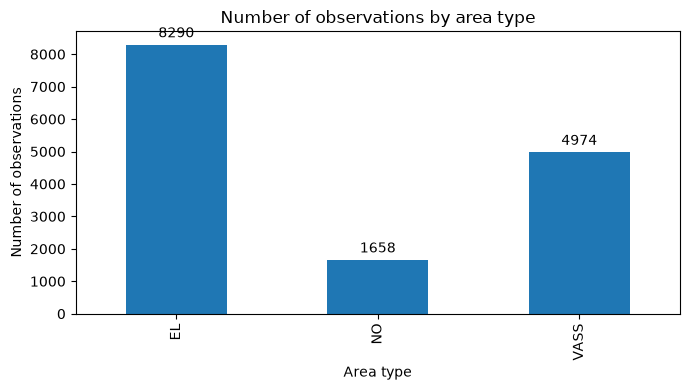

In [4]:
# Count how many observations belong to each area type.
area_type_counts = df['area_type'].value_counts().sort_index()

# A bar chart makes the number of records in each area system easy to compare.
ax = area_type_counts.plot(
    kind='bar',
    color='#1f77b4',
    figsize=(7, 4),
)
ax.set_title('Number of observations by area type')
ax.set_xlabel('Area type')
ax.set_ylabel('Number of observations')
ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()

## 8. Separate plots for measurement columns

The two area systems are alternative ways of grouping the same reservoirs.
Each time-series figure therefore compares electricity price areas (EL) on the
left with watercourse areas (VASS) on the right. The national series (NO-0) is
included in both panels as a shared reference. Capacity is shown as bars rather
than a time series because it is a size measure for each area.


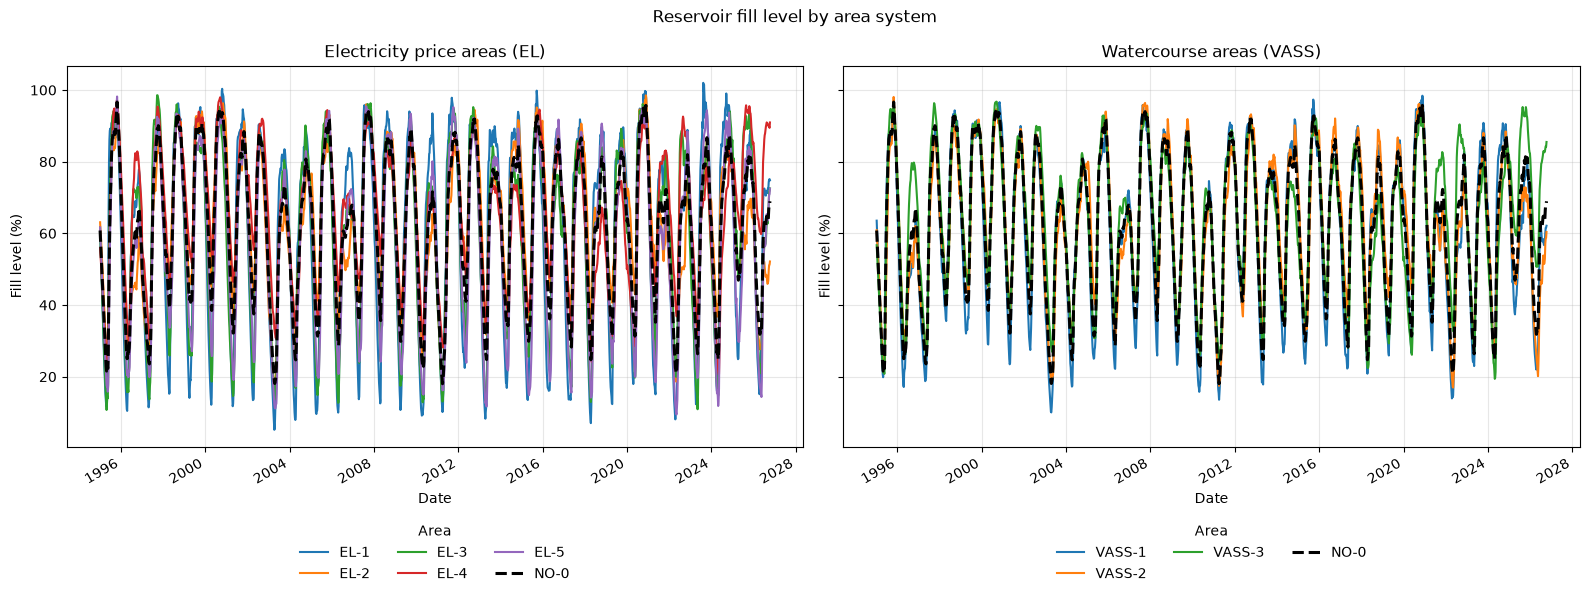

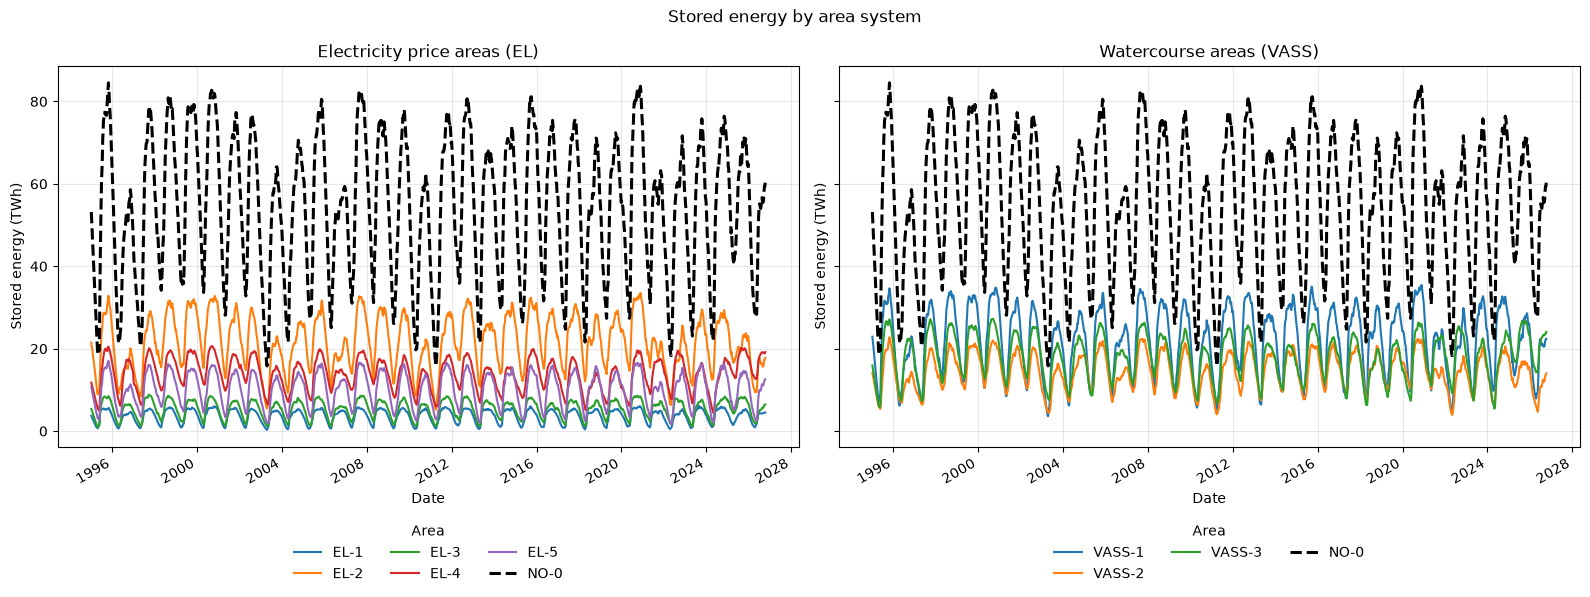

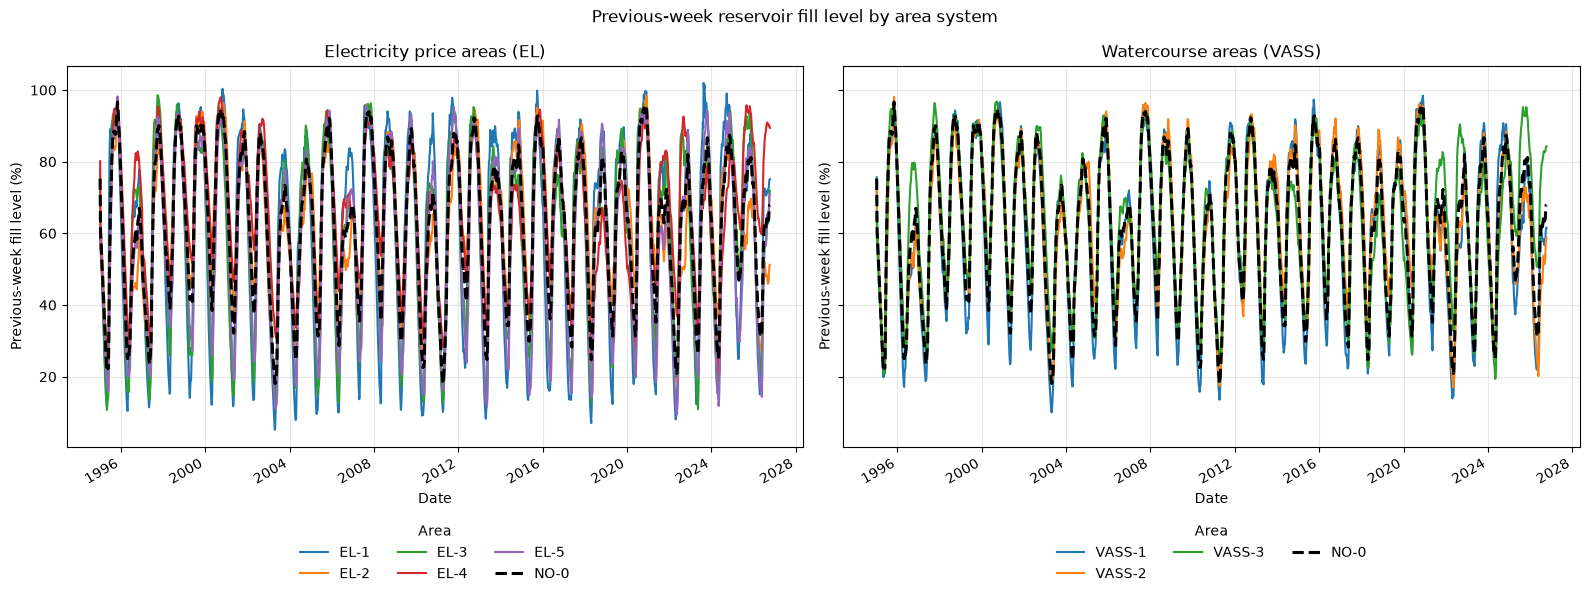

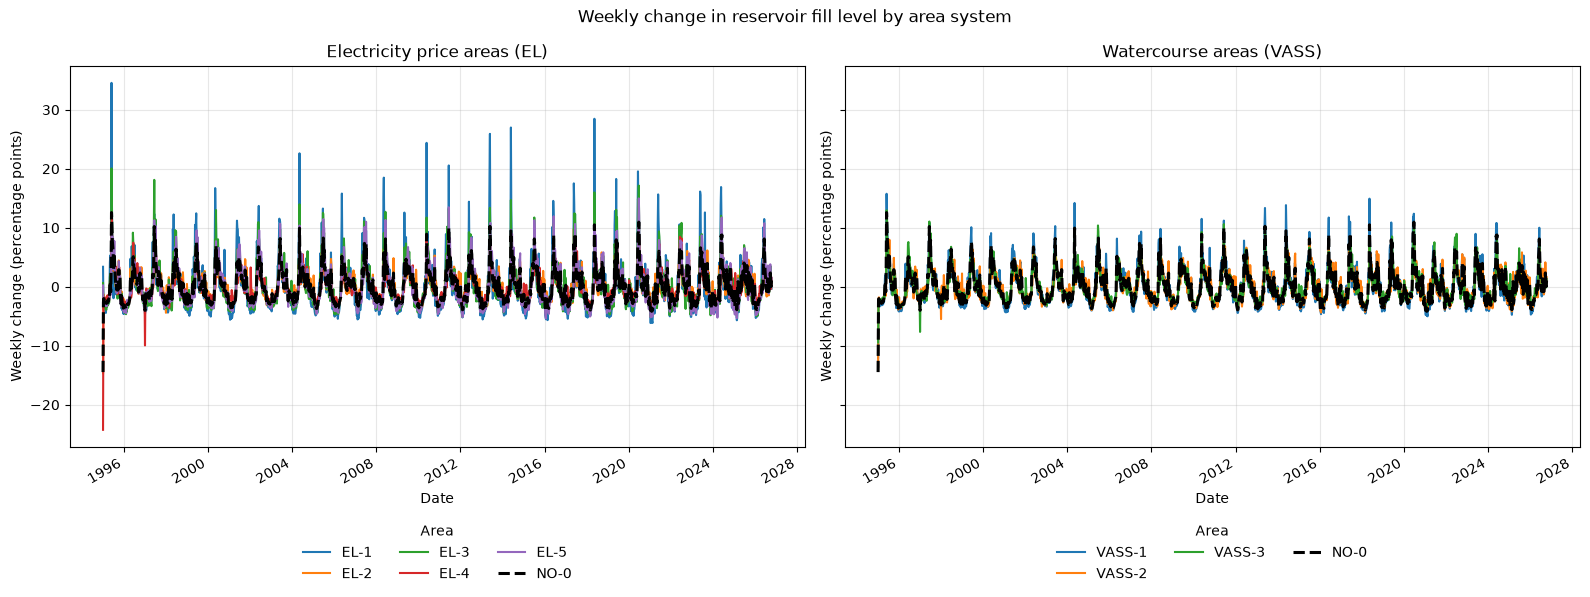

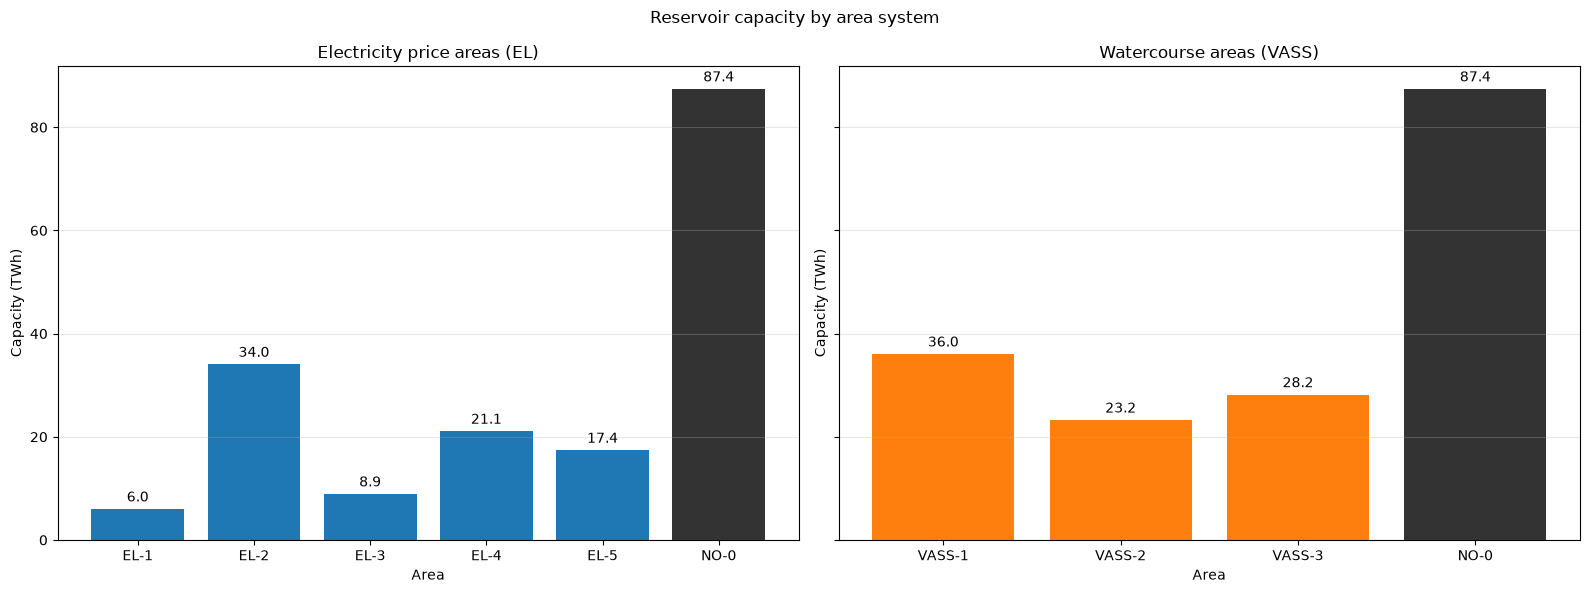

In [5]:
# Create readable labels for the area series and select the national reference.
plot_data = df.assign(
    area_label=df['area_type'] + '-' + df['area_number'].astype(str)
)
national_data = plot_data.loc[
    (plot_data['area_type'] == 'NO') & (plot_data['area_number'] == 0)
].copy()

# Ratios are multiplied by 100 for percent or percentage points; TWh stays as is.
# Capacity is a size measure and gets its own bar chart below.
LINE_PLOT_SETTINGS = {
    'fill_level_ratio': {
        'title': 'Reservoir fill level by area system',
        'y_label': 'Fill level (%)',
        'multiplier': 100,
    },
    'stored_energy_twh': {
        'title': 'Stored energy by area system',
        'y_label': 'Stored energy (TWh)',
        'multiplier': 1,
    },
    'previous_week_fill_level_ratio': {
        'title': 'Previous-week reservoir fill level by area system',
        'y_label': 'Previous-week fill level (%)',
        'multiplier': 100,
    },
    'weekly_fill_level_change': {
        'title': 'Weekly change in reservoir fill level by area system',
        'y_label': 'Weekly change (percentage points)',
        'multiplier': 100,
    },
}

# Draw EL and VASS in separate panels so the alternative area systems are not mixed.
for column, settings in LINE_PLOT_SETTINGS.items():
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

    for ax, area_type, panel_title in [
        (axes[0], 'EL', 'Electricity price areas (EL)'),
        (axes[1], 'VASS', 'Watercourse areas (VASS)'),
    ]:
        area_system_data = plot_data.loc[plot_data['area_type'] == area_type]

        for area_label, area_data in area_system_data.groupby('area_label', sort=True):
            ax.plot(
                area_data['date'],
                area_data[column] * settings['multiplier'],
                label=area_label,
                linewidth=1.5,
            )

        # Draw the national series last, so it remains visible above the area lines.
        ax.plot(
            national_data['date'],
            national_data[column] * settings['multiplier'],
            color='black',
            label='NO-0',
            linewidth=2.2,
            linestyle='--',
        )
        ax.set_title(panel_title)
        ax.set_xlabel('Date')
        ax.set_ylabel(settings['y_label'])
        ax.grid(alpha=0.3)
        ax.legend(
            title='Area',
            loc='upper center',
            bbox_to_anchor=(0.5, -0.17),
            ncol=3,
            frameon=False,
        )

    fig.suptitle(settings['title'], y=0.98)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.subplots_adjust(bottom=0.25)
    plt.show()

# Capacity is a size measure, so compare areas with bars instead of a date axis.
latest_date = plot_data['date'].max()
latest_capacity = plot_data.loc[plot_data['date'] == latest_date].copy()
national_capacity = latest_capacity.loc[
    (latest_capacity['area_type'] == 'NO')
    & (latest_capacity['area_number'] == 0)
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, area_type, panel_title, area_color in [
    (axes[0], 'EL', 'Electricity price areas (EL)', '#1f77b4'),
    (axes[1], 'VASS', 'Watercourse areas (VASS)', '#ff7f0e'),
]:
    area_capacity = latest_capacity.loc[
        latest_capacity['area_type'] == area_type
    ].sort_values('area_number')
    # Add NO-0 beside each regional system as a reference, not as another area.
    comparison_capacity = pd.concat([area_capacity, national_capacity])
    bar_colors = [area_color] * len(area_capacity) + ['#333333']

    bars = ax.bar(
        comparison_capacity['area_label'],
        comparison_capacity['capacity_twh'],
        color=bar_colors,
    )
    ax.bar_label(bars, fmt='%.1f', padding=3)
    ax.set_title(panel_title)
    ax.set_xlabel('Area')
    ax.set_ylabel('Capacity (TWh)')
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Reservoir capacity by area system', y=0.98)
fig.tight_layout()
plt.show()


## 9. Combined multi-axis overview for Norway

The national measurement columns have different units and some are mathematically related. This single figure therefore keeps the original units instead of normalizing them. The top panel uses a percentage axis for fill levels and a TWh axis for stored energy and capacity. The lower panel shows weekly change in percentage points. Together, the two panels provide one readable overview of all five measurement columns.

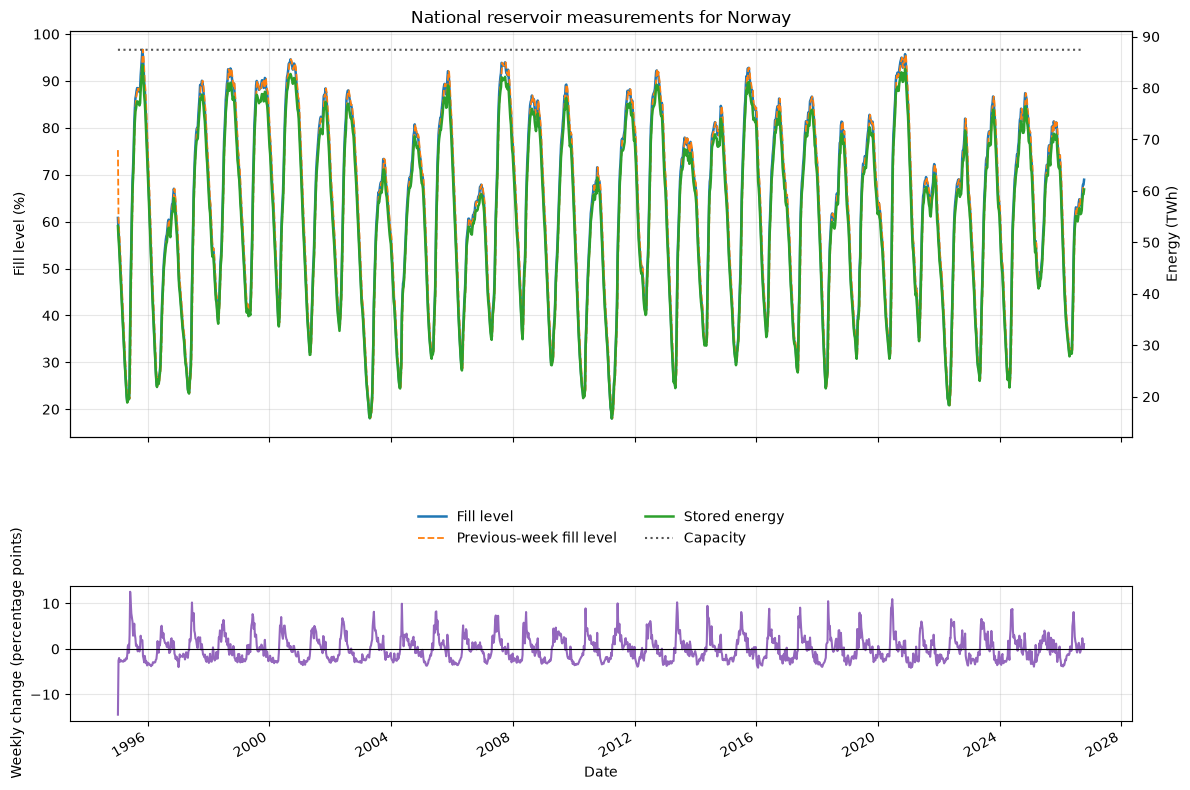

In [6]:
import sys

# Make the reusable project module available when Jupyter starts in notebooks/.
PROJECT_CODE_PATH = PROJECT_ROOT / 'Compulsory Assignments'
if str(PROJECT_CODE_PATH) not in sys.path:
    sys.path.insert(0, str(PROJECT_CODE_PATH))

from modules.reservoir_plotting import plot_national_overview

# Select the single national time series so the combined figure remains readable.
national_data = df.loc[
    (df['area_type'] == 'NO') & (df['area_number'] == 0)
].copy()

# Use the reusable function so the full and short time-period charts share style.
plot_national_overview(
    national_data,
    'National reservoir measurements for Norway',
)


## 10. Detailed overview of the last five years

This version uses the same variables and units as the full-period overview, but only includes the five years leading up to the most recent observation. Fewer observations make recent changes easier to inspect.

Detailed period: 2021-10-17 to 2026-10-11
Observations in detailed period: 261


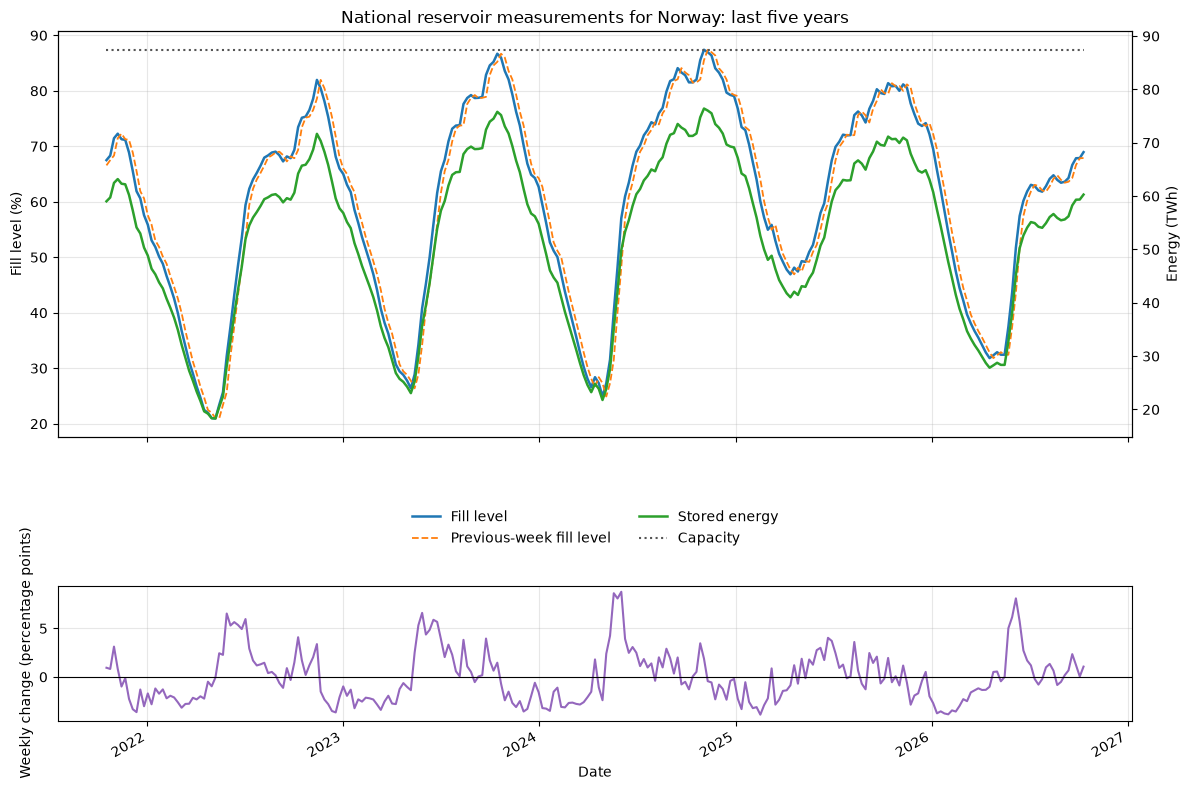

In [7]:
# Find the date five years before the latest available observation.
five_year_start = national_data['date'].max() - pd.DateOffset(years=5)
recent_data = national_data.loc[national_data['date'] >= five_year_start].copy()

print(
    f'Detailed period: {recent_data["date"].min().date()} '
    f'to {recent_data["date"].max().date()}'
)
print(f'Observations in detailed period: {len(recent_data)}')

# Reuse the exact same plot design with only the shorter data period changed.
plot_national_overview(
    recent_data,
    'National reservoir measurements for Norway: last five years',
)


## 11. ENTSO-E physical flows between Norway and neighbouring countries

Here, we fetch the full UTC calendar years **2024** and **2025**, plus **2026 through the last completed UTC day**. ENTSO-E labels the publication TR 12.1.G Physical Flows; the [Postman API entry](https://documenter.getpostman.com/view/7009892/2s93JtP3F6) uses `documentType=A11`. The [ENTSO-E area list](https://transparencyplatform.zendesk.com/hc/en-us/articles/15885757676308-Area-List-with-Energy-Identification-Code-EIC) supplies the country EIC codes.

The API permits at most one year per request. Six country pairs, two directions and three calendar-year windows mean **36 calls** for a full run. Each published average power value (MW) is multiplied by its block duration in hours to obtain energy (MWh). The `country`, `direction`, `year`, and UTC interval columns support later plots. A missing response is reported, not interpreted as zero. 


In [28]:
import tomllib
import xml.etree.ElementTree as ET

import pandas as pd
import requests


# Use country codes for the six neighbours and keep import/export separate.
API_URL = "https://web-api.tp.entsoe.eu/api"
NORWAY_CODE = "10YNO-0--------C"
COUNTRY_CODES = {
    "Denmark": "10Y1001A1001A65H",
    "Finland": "10YFI-1--------U",
    "Germany": "10Y1001A1001A83F",
    "Netherlands": "10YNL----------L",
    "Sweden": "10YSE-1--------K",
    "United Kingdom": "10Y1001A1001A92E",
}
# The XML resolution locates each published point on the time axis.
RESOLUTIONS = {
    "PT15M": pd.Timedelta(minutes=15),
    "PT30M": pd.Timedelta(minutes=30),
    "PT60M": pd.Timedelta(hours=1),
}


def read_entsoe_token(project_root):
    """Read the local ENTSO-E token so requests can authenticate privately."""
    secrets_path = project_root / ".streamlit" / "secrets.toml"
    with secrets_path.open("rb") as secrets_file:
        settings = tomllib.load(secrets_file)
    token = settings.get("entsoe", {}).get("security_token")
    if not token:
        raise ValueError("Set [entsoe].security_token in local secrets.toml.")
    return token


def parse_physical_flows(xml_content, from_area, to_area, start_utc, end_utc):
    """Turn ENTSO-E XML into MW blocks inside the requested UTC period."""
    # A no-data acknowledgement is different from a normal flow document.
    root = ET.fromstring(xml_content)
    if root.tag.endswith("Acknowledgement_MarketDocument"):
        reason = root.findtext(".//{*}Reason/{*}text") or "Unknown acknowledgement"
        if "No matching data" in reason or "No data" in reason:
            return []
        raise ValueError(f"ENTSO-E rejected the request: {reason}")

    rows = []
    for series in root.findall(".//{*}TimeSeries"):
        # A country pair and direction are required for every published series.
        if (series.findtext("{*}out_Domain.mRID") != from_area
                or series.findtext("{*}in_Domain.mRID") != to_area):
            raise ValueError("ENTSO-E returned an unexpected country pair or direction.")
        if series.findtext("{*}quantity_Measure_Unit.name") != "MAW":
            raise ValueError("ENTSO-E returned a power unit other than MW.")
        # The curve type says whether a value lasts one step or until the next change.
        curve_type = series.findtext("{*}curveType")
        if curve_type not in {"A01", "A03"}:
            raise ValueError(f"Unsupported curve type: {curve_type}")

        for period in series.findall("{*}Period"):
            period_start = pd.Timestamp(period.findtext("{*}timeInterval/{*}start"))
            period_end = pd.Timestamp(period.findtext("{*}timeInterval/{*}end"))
            resolution = RESOLUTIONS[period.findtext("{*}resolution")]
            points = period.findall("{*}Point")
            for index, point in enumerate(points):
                # A03 points last until the next change; A01 points last one step.
                position = int(point.findtext("{*}position"))
                block_start = period_start + (position - 1) * resolution
                if curve_type == "A03" and index + 1 < len(points):
                    next_position = int(points[index + 1].findtext("{*}position"))
                    block_end = period_start + (next_position - 1) * resolution
                elif curve_type == "A03":
                    block_end = period_end
                else:
                    block_end = block_start + resolution
                if not period_start <= block_start < block_end <= period_end:
                    raise ValueError("Invalid ENTSO-E point boundaries.")

                # Keep only the part inside our request; yearly windows must not overlap.
                clipped_start = max(block_start, start_utc)
                clipped_end = min(block_end, end_utc)
                if clipped_start < clipped_end:
                    rows.append({
                        "timestamp_utc": clipped_start,
                        "end_utc": clipped_end,
                        "power_mw": float(point.findtext("{*}quantity")),
                        "interval_hours": (clipped_end - clipped_start)
                        / pd.Timedelta(hours=1),
                    })
    return rows


# Request full 2024 and 2025, plus completed UTC days of 2026.
period_start_utc = pd.Timestamp("2024-01-01", tz="UTC")
period_end_utc = pd.Timestamp.now(tz="UTC").normalize()
year_windows = [
    (pd.Timestamp(f"{year}-01-01", tz="UTC"),
     min(pd.Timestamp(f"{year + 1}-01-01", tz="UTC"), period_end_utc))
    for year in (2024, 2025, 2026)
]
year_windows = [(start, end) for start, end in year_windows if start < end]
security_token = read_entsoe_token(PROJECT_ROOT)

flow_rows = []
missing_queries = []
request_number = 0
# One request is needed for each country, direction, and year window.
request_total = len(COUNTRY_CODES) * 2 * len(year_windows)
for country, foreign_code in COUNTRY_CODES.items():
    for direction, from_area, to_area in (
        ("export", NORWAY_CODE, foreign_code),
        ("import", foreign_code, NORWAY_CODE),
    ):
        for start_utc, end_utc in year_windows:
            request_number += 1
            print(f"{request_number}/{request_total}: {country} {direction} "
                  f"{start_utc.date()} to {end_utc.date()}", flush=True)
            parameters = {
                "securityToken": security_token,
                "documentType": "A11",
                "out_Domain": from_area,
                "in_Domain": to_area,
                "periodStart": start_utc.strftime("%Y%m%d%H%M"),
                "periodEnd": end_utc.strftime("%Y%m%d%H%M"),
            }
            try:
                response = requests.get(API_URL, params=parameters, timeout=60)
            except requests.RequestException:
                # Request exceptions can include the token-bearing URL.
                raise RuntimeError("ENTSO-E request failed; check the connection.") from None
            if response.status_code != 200:
                raise RuntimeError(f"ENTSO-E returned HTTP {response.status_code}.")

            rows = parse_physical_flows(
                response.content, from_area, to_area, start_utc, end_utc
            )
            if not rows:
                missing_queries.append((country, direction, start_utc.date()))
            # Add readable labels before combining the API responses.
            for row in rows:
                row["country"] = country
                row["direction"] = direction
            flow_rows.extend(rows)

if not flow_rows:
    raise ValueError("ENTSO-E returned no physical-flow observations.")
physical_flows = pd.DataFrame(flow_rows)
# Calendar year is based on UTC, matching the request boundaries.
physical_flows["year"] = physical_flows["timestamp_utc"].dt.year
# Average MW multiplied by the block duration in hours gives MWh.
physical_flows["energy_mwh"] = (
    physical_flows["power_mw"] * physical_flows["interval_hours"]
)
# Add MWh within each country, year, and direction before converting to TWh.
energy_by_country = (
    physical_flows.groupby(["country", "year", "direction"], as_index=False)["energy_mwh"]
    .sum()
)
energy_by_country["energy_twh"] = energy_by_country["energy_mwh"] / 1_000_000
energy_totals = (
    energy_by_country.groupby(["year", "direction"], as_index=False)["energy_twh"].sum()
)

print(f"UTC period: {period_start_utc} to {period_end_utc} (end excluded)")
if missing_queries:
    print("Warning: no published data for these requests; totals may be incomplete:")
    display(pd.DataFrame(missing_queries, columns=["country", "direction", "year_start"]))
display(energy_by_country[["country", "year", "direction", "energy_twh"]])
display(energy_totals)


1/36: Denmark export 2024-01-01 to 2025-01-01


2/36: Denmark export 2025-01-01 to 2026-01-01
3/36: Denmark export 2026-01-01 to 2026-10-20
4/36: Denmark import 2024-01-01 to 2025-01-01
5/36: Denmark import 2025-01-01 to 2026-01-01
6/36: Denmark import 2026-01-01 to 2026-10-20
7/36: Finland export 2024-01-01 to 2025-01-01
8/36: Finland export 2025-01-01 to 2026-01-01
9/36: Finland export 2026-01-01 to 2026-10-20
10/36: Finland import 2024-01-01 to 2025-01-01
11/36: Finland import 2025-01-01 to 2026-01-01
12/36: Finland import 2026-01-01 to 2026-10-20
13/36: Germany export 2024-01-01 to 2025-01-01
14/36: Germany export 2025-01-01 to 2026-01-01
15/36: Germany export 2026-01-01 to 2026-10-20
16/36: Germany import 2024-01-01 to 2025-01-01
17/36: Germany import 2025-01-01 to 2026-01-01
18/36: Germany import 2026-01-01 to 2026-10-20
19/36: Netherlands export 2024-01-01 to 2025-01-01
20/36: Netherlands export 2025-01-01 to 2026-01-01
21/36: Netherlands export 2026-01-01 to 2026-10-20
22/36: Netherlands import 2024-01-01 to 2025-01-01
23/36

,country,year,direction,energy_twh
0,Denmark,2024,export,8.119131
1,Denmark,2024,import,1.652847
2,Denmark,2025,export,8.157340
3,Denmark,2025,import,1.153574
4,Denmark,2026,export,3.866731
5,Denmark,2026,import,2.680250
6,Finland,2024,export,0.256701
7,Finland,2024,import,0.030347
8,Finland,2025,export,0.277224
9,Finland,2025,import,0.047301


,year,direction,energy_twh
0,2024,export,32.094326
1,2024,import,14.202912
2,2025,export,33.376520
3,2025,import,10.921449
4,2026,export,18.360066
5,2026,import,13.954688


## 12. Store country flows in one Cassandra table with Spark

The next cell creates the local `ind320_ca2.country_flows_utc` table and writes one row per published physical-flow block. Each row has a country, calendar year, direction, UTC start/end in milliseconds, average power (MW), and energy (MWh). The year is part of the Cassandra key so Spark can select a year efficiently.


In [21]:
import subprocess

from pyspark.sql import SparkSession


KEYSPACE = "ind320_ca2"
TABLE = "country_flows_utc"

# Stop before any database write if an API request returned no data.
if missing_queries:
    raise ValueError("Missing ENTSO-E responses; review the API cell before storing data.")
if physical_flows.empty:
    raise ValueError("Run the ENTSO-E cell before storing data.")

# The primary key identifies one country, year, direction, and start time.
# Integer UTC times avoid local-time conversion in the Spark connector.
setup_cql = """
CREATE KEYSPACE IF NOT EXISTS ind320_ca2
WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1};
CREATE TABLE IF NOT EXISTS ind320_ca2.country_flows_utc (
    country text,
    year int,
    direction text,
    timestamp_ms bigint,
    end_ms bigint,
    power_mw double,
    energy_mwh double,
    PRIMARY KEY ((country, year), direction, timestamp_ms)
);
"""
subprocess.run(
    ["docker", "exec", "-i", "cassandra", "cqlsh"],
    input=setup_cql, text=True, check=True, timeout=60,
)

# Use the connector version compatible with the installed Spark version.
spark = (
    SparkSession.builder.appName("IND320-CA2-PhysicalFlows")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.extensions", "com.datastax.spark.connector.CassandraSparkExtensions")
    .getOrCreate()
)
spark.conf.set("spark.sql.session.timeZone", "UTC")
# Arrow transfers this Pandas table to Spark without the Python worker failure
# seen on this Windows/Python setup.
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")
spark.conf.set("spark.sql.execution.arrow.pyspark.fallback.enabled", "false")

spark_input = physical_flows[
    ["country", "year", "direction", "power_mw", "energy_mwh"]
].copy()
# Convert timezone-aware UTC times explicitly to milliseconds since 1970;
# Cassandra stores the corresponding milliseconds as integers.
spark_input["timestamp_ms"] = physical_flows["timestamp_utc"].dt.as_unit("ms").astype("int64")
spark_input["end_ms"] = physical_flows["end_utc"].dt.as_unit("ms").astype("int64")
if (spark_input["timestamp_ms"] >= spark_input["end_ms"]).any():
    raise ValueError("A physical-flow block has an invalid UTC interval.")
# Repeated primary keys would silently replace rows in Cassandra.
key_columns = ["country", "year", "direction", "timestamp_ms"]
if spark_input.duplicated(key_columns).any():
    raise ValueError("Duplicate Cassandra primary keys in the API data.")

# Spark writes the prepared rows into the local Cassandra table.
spark.createDataFrame(spark_input).write.format("org.apache.spark.sql.cassandra") \
    .options(table=TABLE, keyspace=KEYSPACE).mode("append").save()
print(f"Wrote {len(spark_input):,} flow rows to local {KEYSPACE}.{TABLE}.")


Wrote 315,438 flow rows to local ind320_ca2.country_flows_utc.


## 13. Extract plot columns from Cassandra with Spark

Spark reads the saved integer UTC times from `country_flows_utc` and converts them to timestamp columns for plotting. `annual_energy_for_pie` sums MWh for each full calendar year, country, and direction. `january_flows_for_lines` keeps MW and UTC times for January. The 2026 year is incomplete and is not used for a full-year pie chart. These values describe cross-border physical flows, not electricity production.


In [22]:
from pyspark.sql import functions as F

# Read from Cassandra and restore human-readable UTC timestamps in Spark.
stored_flows = spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table=TABLE, keyspace=KEYSPACE).load()
# Confirm that Cassandra contains the same number of blocks we just wrote.
if stored_flows.count() != len(spark_input):
    raise ValueError("Cassandra row count differs from the API data.")
# Keep the fields needed for the plots and turn millisecond integers into dates.
plot_columns = stored_flows.select(
    "country", "year", "direction",
    F.expr("timestamp_millis(timestamp_ms)").alias("timestamp_utc"),
    F.expr("timestamp_millis(end_ms)").alias("end_utc"),
    "power_mw", "energy_mwh",
)

# Verify the source period before making totals or exporting to MongoDB.
source_start_ms = int(period_start_utc.timestamp() * 1000)
source_end_ms = int(period_end_utc.timestamp() * 1000)
bad_rows = stored_flows.filter(
    (F.col("timestamp_ms") < source_start_ms)
    | (F.col("timestamp_ms") >= source_end_ms)
    | (F.col("end_ms") > source_end_ms)
    | (F.col("end_ms") <= F.col("timestamp_ms"))
    | (F.year(F.expr("timestamp_millis(timestamp_ms)")) != F.col("year"))
)
if bad_rows.limit(1).count():
    raise ValueError("Cassandra contains a flow block outside the UTC API period.")

# Sum interval energy for the two complete calendar years.
annual_energy_for_pie = (
    plot_columns.filter(F.col("year").isin(2024, 2025))
    .groupBy("country", "year", "direction")
    .agg(F.sum("energy_mwh").alias("energy_mwh"))
)

# Keep all countries and directions for selectable January lines.
january_flows_for_lines = (
    plot_columns.filter(F.month("timestamp_utc") == 1)
    .select("country", "year", "direction", "timestamp_utc", "end_utc", "power_mw")
)
display(annual_energy_for_pie.orderBy("year", "country", "direction").toPandas())
print("January flow columns:", january_flows_for_lines.columns)


,country,year,direction,energy_mwh
0,Denmark,2024,export,8.119131e+06
1,Denmark,2024,import,1.652847e+06
2,Finland,2024,export,2.567007e+05
3,Finland,2024,import,3.034699e+04
4,Germany,2024,export,6.998108e+06
5,Germany,2024,import,1.218497e+06
6,Netherlands,2024,export,3.496699e+06
7,Netherlands,2024,import,5.961103e+05
8,Sweden,2024,export,3.034943e+06
9,Sweden,2024,import,1.043180e+07


January flow columns: ['country', 'year', 'direction', 'timestamp_utc', 'end_utc', 'power_mw']


## 14. Annual cross-border energy for one country

Choose a full calendar year and one foreign country. The pie chart compares the total physical-flow energy **into Norway (import)** and **out of Norway (export)** for that country pair, in TWh. This is cross-border transfer, not electricity production. The source is `annual_energy_for_pie`, aggregated with Spark after reading Cassandra.


In [23]:
import plotly.express as px


# Change these two choices to inspect another complete year or country.
selected_year = 2025
selected_country = "Sweden"
if selected_year not in (2024, 2025) or selected_country not in COUNTRY_CODES:
    raise ValueError("Choose 2024 or 2025 and a country from COUNTRY_CODES.")

# Keep the annual aggregation in Spark and collect only the two plot values.
pie_data = (
    annual_energy_for_pie
    .filter((F.col("year") == selected_year) & (F.col("country") == selected_country))
    .toPandas()
)
if set(pie_data["direction"]) != {"import", "export"}:
    raise ValueError("Both import and export totals are needed for this pie chart.")
# Rename directions for readers and convert MWh to TWh for the chart.
pie_data["flow"] = pie_data["direction"].map({
    "import": "Into Norway", "export": "Out of Norway",
})
pie_data["energy_twh"] = pie_data["energy_mwh"] / 1_000_000

annual_pie = px.pie(
    pie_data, names="flow", values="energy_twh",
    title=f"Physical flows between Norway and {selected_country}, {selected_year}",
    labels={"energy_twh": "Energy (TWh)", "flow": "Direction"},
)
annual_pie.update_traces(textinfo="label+percent")
annual_pie.show()


## 15. Physical-flow power during January

Choose one or more countries in `selected_countries`. Each country and direction receives a separate line for January of `selected_year`. The vertical axis is **power (MW)**, not annual energy. UTC timestamps and stepped lines show that a published value applies until the next time block. 

In [24]:
# Start with the same country as the pie chart; add names to compare borders.
selected_countries = [selected_country]
if not selected_countries or not set(selected_countries).issubset(COUNTRY_CODES):
    raise ValueError("Select one or more countries from COUNTRY_CODES.")

# Collect only the selected January blocks from the Spark/Cassandra extract.
january_data = (
    january_flows_for_lines
    .filter((F.col("year") == selected_year)
            & F.col("country").isin(selected_countries))
    .orderBy("country", "direction", "timestamp_utc")
    .toPandas()
)
if january_data.empty:
    raise ValueError("No January data for the selected year and countries.")

# Check the first and last UTC times, plus every join between blocks.
january_start = pd.Timestamp(f"{selected_year}-01-01")
february_start = pd.Timestamp(f"{selected_year}-02-01")
line_parts = []
for (country, direction), blocks in january_data.groupby(["country", "direction"]):
    blocks = blocks.sort_values("timestamp_utc").copy()
    # A stepped line needs one final point to show the end of its last block.
    block_ends = blocks["end_utc"].clip(upper=february_start)
    if (blocks["timestamp_utc"].iloc[0] != january_start
            or block_ends.iloc[-1] != february_start
            or (blocks["timestamp_utc"].iloc[1:].reset_index(drop=True)
                != block_ends.iloc[:-1].reset_index(drop=True)).any()):
        raise ValueError(f"Incomplete January coverage for {country} {direction}.")
    blocks["series"] = (f"{country} / "
                        + ("Into Norway" if direction == "import" else "Out of Norway"))
    endpoint = blocks.iloc[[-1]].copy()
    endpoint["timestamp_utc"] = february_start
    line_parts.append(pd.concat([blocks, endpoint], ignore_index=True))

line_data = pd.concat(line_parts, ignore_index=True)
# A stepped line shows that each MW value applies until its block ends.
january_lines = px.line(
    line_data, x="timestamp_utc", y="power_mw", color="series", line_shape="hv",
    title=f"Physical flows to and from Norway, January {selected_year}",
    labels={"timestamp_utc": "Time (UTC)", "power_mw": "Power (MW)",
            "series": "Country / direction"},
)
january_lines.show()


## 16. Save monthly Spark extracts in MongoDB

The hosted app needs country, year, and month filters. This cell groups the blocks into one MongoDB document per country, year, month, and direction. Each document holds a monthly MWh total for the pie chart and its MW blocks for line plots. A block that crosses a UTC month boundary is split between those months. The 2026 data ends at the last completed UTC day.



In [25]:
import tomllib
from datetime import timezone

from pymongo import MongoClient, ReplaceOne
from pymongo.server_api import ServerApi


def utc_datetime(value):
    """Mark a Spark-to-Pandas date as UTC before sending it to MongoDB."""
    return value.to_pydatetime().replace(tzinfo=timezone.utc)


# Read the private connection string without displaying it in notebook output.
with (PROJECT_ROOT / ".streamlit" / "secrets.toml").open("rb") as secrets_file:
    mongo_uri = tomllib.load(secrets_file)["mongo"]["uri"]
if not mongo_uri or "<db_password>" in mongo_uri:
    raise ValueError("Set [mongo].uri in local .streamlit/secrets.toml.")

# Spark and Pandas exchange naive timestamps in the UTC session time zone.
spark.conf.set("spark.sql.session.timeZone", "UTC")
client = MongoClient(mongo_uri, server_api=ServerApi("1"),
                     serverSelectionTimeoutMS=10000)
try:
    # Check the connection before creating the month lookup index.
    client.admin.command("ping")
    collection = client["ind320_ca2"]["monthly_flows"]
    collection.create_index(
        [("country", 1), ("year", 1), ("month", 1), ("direction", 1)],
        unique=True,
    )

    saved_months = 0
    for year in (2024, 2025, 2026):
        # Convert one year at a time so the whole extract is not held in Pandas.
        year_data = plot_columns.filter(F.col("year") == year).toPandas()
        # Group blocks into one document per country, month, and direction.
        monthly_documents = {}
        for row in year_data.itertuples(index=False):
            start = row.timestamp_utc
            end = row.end_utc
            while start < end:
                # Split a block at midnight UTC on the first day of next month.
                next_month = (start.to_period("M") + 1).to_timestamp()
                part_end = min(end, next_month)
                key = (row.country, start.year, start.month, row.direction)
                if key not in monthly_documents:
                    monthly_documents[key] = {
                        "country": row.country, "year": int(start.year),
                        "month": int(start.month), "direction": row.direction,
                        "energy_mwh": 0.0, "blocks": [],
                    }
                document = monthly_documents[key]
                # MW times this part of the block in hours gives its MWh.
                document["energy_mwh"] += (
                    float(row.power_mw) * ((part_end - start) / pd.Timedelta(hours=1))
                )
                document["blocks"].append({
                    "timestamp_utc": utc_datetime(start),
                    "end_utc": utc_datetime(part_end),
                    "power_mw": float(row.power_mw),
                })
                start = part_end

        # Replace each month on reruns so revised blocks do not linger.
        writes = []
        for key, document in monthly_documents.items():
            document["blocks"].sort(key=lambda block: block["timestamp_utc"])
            selector = dict(zip(("country", "year", "month", "direction"), key))
            writes.append(ReplaceOne(selector, document, upsert=True))
        if writes:
            collection.bulk_write(writes, ordered=False)
        saved_months += len(writes)
        print(f"Saved {len(writes)} monthly documents for {year}.", flush=True)

    # Remove old out-of-period documents after the corrected months are saved.
    collection.delete_many({"year": {"$lt": 2024}})
    print(f"Saved {saved_months} monthly documents to MongoDB.")
finally:
    client.close()


Saved 144 monthly documents for 2024.
Saved 144 monthly documents for 2025.
Saved 120 monthly documents for 2026.
Saved 408 monthly documents to MongoDB.
